# Spam Classifier Exploration — Combined Team Analysis

**Submission model:** 50% binned logistic regression, 25% KNN-imputed RBF SVM,
and 25% logistic regression with interactions. The executable model remains in
`classifySpam.py`.

This notebook combines Ha's model comparisons and component checks with selected
data exploration and error-analysis ideas from Ethan's
`CSDS_340_Case_Study_1_Exploration.ipynb` (branch `Ethan`, commit `4c10633`).
Ethan's frozen 60% histogram boosting / 40% random forest recipe is compared
on the same rows, folds, metrics, and installed scikit-learn version.

Keep `spamTrain1.csv` and `classifySpam.py` beside this notebook and run top to bottom.
`QUICK_RUN=False` runs 10 seeds × 5 folds; `True` is a five-fold smoke check.
Required packages: NumPy, pandas, matplotlib, scikit-learn, IPython, and threadpoolctl.
The new exploration uses the existing **1,125 development emails**; the 375
previously examined audit emails remain excluded. These are development results,
not an independent estimate on the instructor's hidden test set.

In [1]:
from pathlib import Path
import hashlib
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, PolynomialFeatures
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from threadpoolctl import threadpool_limits

warnings.filterwarnings('ignore', category=FutureWarning,
                       message='The `probability` parameter was deprecated')
QUICK_RUN = False
seeds = [19] if QUICK_RUN else [19, 43, 101, 521, 991, 2011, 4001, 7001, 12007, 19937]
print(f'scikit-learn {sklearn.__version__}; {5 * len(seeds)} folds per model.')

scikit-learn 1.9.0; 50 folds per model.


## 1. Data Exploration

Each email has **30 word-frequency features** and a label: `0` = ham, `1` = spam.
**`-1` means missing. `0` means the word was observed to be absent.** Treating
them as the same value would discard information.

We retain the original split: **1,125 development emails** and **375 previously
examined audit emails**.

In [2]:
required = ('spamTrain1.csv', 'classifySpam.py')
missing_files = [name for name in required if not Path(name).exists()]
if missing_files:
    raise FileNotFoundError('Place these files beside the notebook: ' + ', '.join(missing_files))

from classifySpam import predictTest

raw = np.loadtxt('spamTrain1.csv', delimiter=',')
if raw.ndim != 2 or raw.shape[1] != 31 or not np.isin(raw[:, -1], [0, 1]).all():
    raise ValueError('Expected 30 features and one 0/1 label column, without a header.')
if not np.isfinite(raw).all() or ((raw[:, :-1] < 0) & (raw[:, :-1] != -1)).any():
    raise ValueError('Features must be nonnegative, with -1 for missing values.')
development, audit = train_test_split(
    np.arange(len(raw)), test_size=0.25, stratify=raw[:, -1], random_state=3402026)
X, y = raw[development, :-1], raw[development, -1].astype(int)

display(pd.Series({
    'Development emails': len(X),
    'Excluded audit emails': len(audit),
    'Spam in development (%)': round(100 * y.mean(), 1),
    'Missing entries in development (%)': round(100 * (X == -1).mean(), 1),
    'Zeros among observed entries (%)': round(100 * (X == 0).sum() / (X >= 0).sum(), 1),
}, name='Data overview').to_frame())

,Data overview
Development emails,1125.0
Excluded audit emails,375.0
Spam in development (%),41.4
Missing entries in development (%),20.1
Zeros among observed entries (%),81.9


### 1.1 Class balance, missing measurements, and observed zeros

Adapted from Ethan's exploration (`Ethan`, commit `4c10633`), using **only our
1,125 development emails**. The 375 excluded audit emails are not inspected here.
Missing percentages use all feature entries; zero percentages use **observed entries
only**. A missing value is unknown, whereas an observed zero says the word is absent.
Class balance also explains why accuracy alone is not our selection metric.

,Emails,Missing entries (%),Zeros among observed (%)
Class,,,
Ham,659,20.10,85.02
Spam,466,20.11,77.60


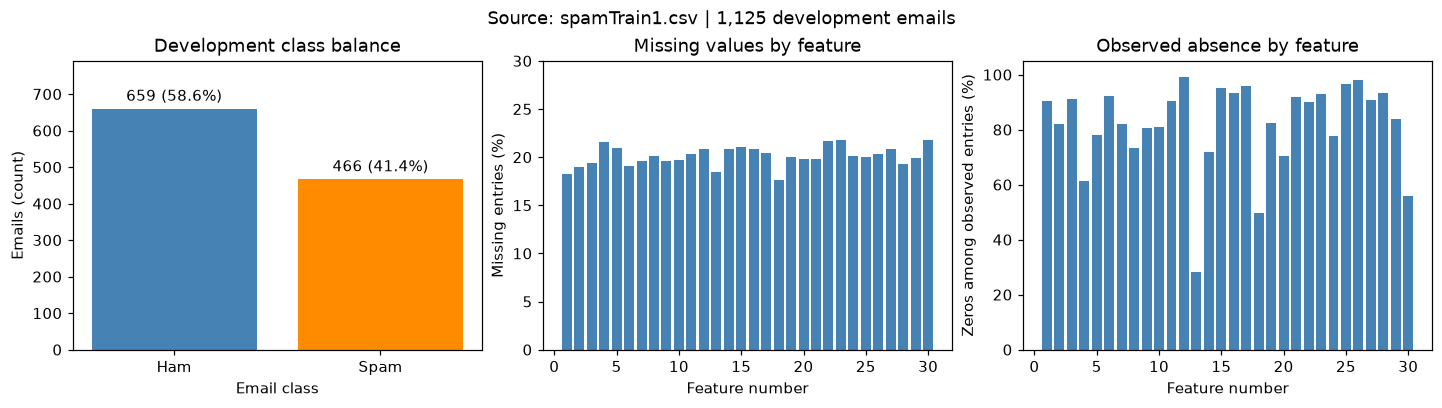

In [3]:
feature_names = [f'Feature {i:02d}' for i in range(1, X.shape[1] + 1)]
observed = X >= 0
missing_mask = X == -1
observed_counts = observed.sum(axis=0)
missing_percent = 100 * missing_mask.mean(axis=0)
zero_percent = np.divide(100 * (X == 0).sum(axis=0), observed_counts,
                         out=np.full(X.shape[1], np.nan), where=observed_counts > 0)
class_summary = pd.DataFrame([
    {'Class': name, 'Emails': int((y == label).sum()),
     'Missing entries (%)': 100 * missing_mask[y == label].mean(),
     'Zeros among observed (%)': 100 * (X[y == label] == 0).sum() / observed[y == label].sum()}
    for label, name in [(0, 'Ham'), (1, 'Spam')]
]).set_index('Class')
display(class_summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
counts = class_summary['Emails']
bars = axes[0].bar(counts.index, counts.values, color=['steelblue', 'darkorange'])
axes[0].bar_label(bars, labels=[f'{v} ({v / len(y):.1%})' for v in counts], padding=3)
axes[0].set(xlabel='Email class', ylabel='Emails (count)', title='Development class balance',
            ylim=(0, counts.max() * 1.2))
feature_numbers = np.arange(1, X.shape[1] + 1)
axes[1].bar(feature_numbers, missing_percent, color='steelblue')
axes[1].set(xlabel='Feature number', ylabel='Missing entries (%)',
            title='Missing values by feature', ylim=(0, max(30, missing_percent.max() * 1.1)))
axes[2].bar(feature_numbers, zero_percent, color='steelblue')
axes[2].set(xlabel='Feature number', ylabel='Zeros among observed entries (%)',
            title='Observed absence by feature', ylim=(0, 105))
fig.suptitle(f'Source: spamTrain1.csv | {len(X):,} development emails')
plt.show()

### 1.2 Word presence and skewed frequencies

Compare presence rates **among emails where that feature was observed**. The eight
largest absolute ham/spam gaps are shown below. The two frequency plots use the
largest gaps and include observed zeros, applying the same `log1p(1000 × frequency)`
transform as our classifier. This makes small positive frequencies easier to inspect
without discarding absence.

These feature choices use development labels and are descriptive, not an independent
feature-selection test. Features are anonymous IDs; we cannot infer specific words
or causal effects from them. The classifier still uses all 30 features.

,Feature,Missing (%),Zero among observed (%),Presence | ham (%),Presence | spam (%),Spam minus ham (pp)
19,Feature 20,19.82,70.51,10.08,56.65,46.57
3,Feature 04,21.60,61.45,21.33,63.87,42.53
8,Feature 09,19.64,80.53,2.10,43.31,41.20
29,Feature 30,21.78,56.02,28.76,65.75,36.98
7,Feature 08,20.09,73.19,13.65,44.85,31.20
4,Feature 05,20.98,77.95,9.45,40.56,31.10
9,Feature 10,19.73,80.84,8.58,34.60,26.02
28,Feature 29,19.91,83.91,6.11,29.97,23.87


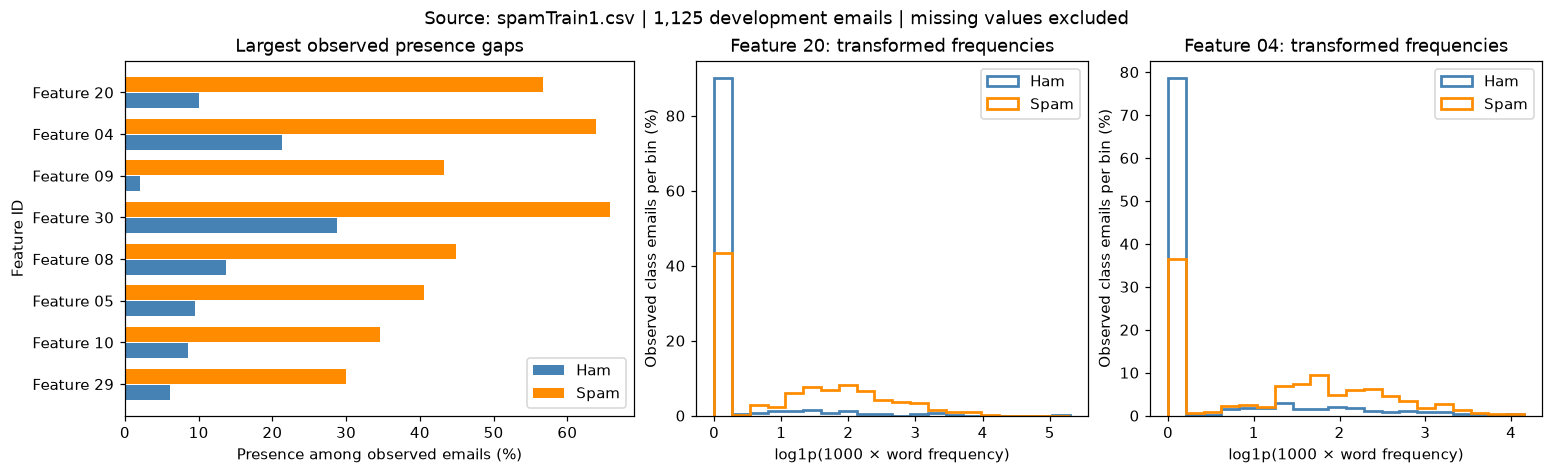

In [4]:
presence_by_class = {}
for label, name in [(0, 'Ham'), (1, 'Spam')]:
    denominator = observed[y == label].sum(axis=0)
    presence_by_class[name] = np.divide(
        100 * (X[y == label] > 0).sum(axis=0), denominator,
        out=np.full(X.shape[1], np.nan), where=denominator > 0)
feature_stats = pd.DataFrame({
    'Feature': feature_names,
    'Missing (%)': missing_percent,
    'Zero among observed (%)': zero_percent,
    'Presence | ham (%)': presence_by_class['Ham'],
    'Presence | spam (%)': presence_by_class['Spam'],
})
feature_stats['Spam minus ham (pp)'] = (
    feature_stats['Presence | spam (%)'] - feature_stats['Presence | ham (%)'])
ranked_features = feature_stats.sort_values('Spam minus ham (pp)', key=np.abs, ascending=False)
display(ranked_features.head(8).round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True,
                         gridspec_kw={'width_ratios': [1.3, 1, 1]})
top_features = ranked_features.head(8).iloc[::-1]
positions = np.arange(len(top_features))
for offset, name, color in [(-.19, 'Ham', 'steelblue'), (.19, 'Spam', 'darkorange')]:
    axes[0].barh(positions + offset, top_features[f'Presence | {name.lower()} (%)'],
                 height=.36, label=name, color=color)
axes[0].set(yticks=positions, yticklabels=top_features['Feature'],
            xlabel='Presence among observed emails (%)', ylabel='Feature ID',
            title='Largest observed presence gaps')
axes[0].legend()
for ax, column_index in zip(axes[1:], ranked_features.index[:2]):
    all_observed = np.log1p(1000 * X[observed[:, column_index], column_index])
    edges = np.linspace(0, max(1, all_observed.max()), 21)
    for label, name, color in [(0, 'Ham', 'steelblue'), (1, 'Spam', 'darkorange')]:
        values = X[(y == label) & observed[:, column_index], column_index]
        transformed = np.log1p(1000 * values)
        ax.hist(transformed, bins=edges, weights=np.full(len(values), 100 / len(values)),
                histtype='step', linewidth=1.8, label=name, color=color)
    ax.set(title=f'{feature_names[column_index]}: transformed frequencies',
           xlabel='log1p(1000 × word frequency)', ylabel='Observed class emails per bin (%)')
    ax.legend()
fig.suptitle(f'Source: spamTrain1.csv | {len(X):,} development emails | missing values excluded')
plt.show()

## 2. Candidate models and a common evaluation protocol

We retain Ha's **11 alternatives and three selected components**, and add Ethan's
two tree components. The two final ensembles are computed from those components'
probability outputs without fitting extra models.

Every learned transform is fitted inside the training fold. Both branches treat
`-1` as missing and preserve observed zero. Ha uses bins, log frequencies, presence,
and interactions; Ethan uses native missing routing in boosting and median
imputation plus missing indicators in the forest.

The headline metrics are the **mean across validation folds** of ROC AUC and
linearly interpolated TPR at FPR=0.01, matching the supplied evaluator's metric.
Ethan's original notebook used pooled out-of-fold metrics over all 1,500 emails;
those old headline scores are not directly comparable to these fold means.

In [5]:
def missing_to_nan(values):
    """Preserve observed zeros; convert only the missing-value marker."""
    return np.where(np.asarray(values) == -1, np.nan, values).astype(float)


def log_frequencies(values):
    return np.log1p(1000 * missing_to_nan(values))


def log_and_presence(values):
    values = missing_to_nan(values)
    presence = np.where(np.isnan(values), np.nan, (values > 0).astype(float))
    return np.hstack((np.log1p(1000 * values), presence))


class ZeroAwareBins(TransformerMixin, BaseEstimator):
    """Encode absent/low/high frequency and presence, using training priors for missing values."""

    def fit(self, values, labels=None):
        self.edges_, self.priors_ = [], []
        for column in missing_to_nan(values).T:
            observed = column[np.isfinite(column)]
            positive = observed[observed > 0]
            if len(positive):
                edges = np.unique(np.expm1(np.linspace(
                    np.log1p(1000 * positive.min()),
                    np.log1p(1000 * positive.max()), 3,
                )[1:-1]) / 1000)
            else:
                edges = np.array([])
            codes = np.where(observed > 0, 1 + np.searchsorted(edges, observed, side='right'), 0)
            counts = np.bincount(codes, minlength=len(edges) + 2).astype(float)
            if not counts.sum():
                counts[0] = 1  # Entirely missing training column: default to absence.
            self.edges_.append(edges)
            self.priors_.append(counts / counts.sum())
        return self

    def transform(self, values):
        columns = []
        for column, edges, prior in zip(missing_to_nan(values).T, self.edges_, self.priors_):
            codes = np.where(column > 0, 1 + np.searchsorted(edges, column, side='right'), 0)
            encoded = np.eye(len(prior))[codes]
            encoded[np.isnan(column)] = prior
            columns.append(np.column_stack((1 - encoded[:, 0], encoded)))
        return np.hstack(columns)


def component_models():
    """Return fresh, unfitted pipelines; each fold learns its own preprocessing."""
    return {
        'Binned logistic regression': make_pipeline(
            ZeroAwareBins(),
            LogisticRegression(C=1, max_iter=3000, random_state=340),
        ),
        'RBF SVM (KNN imputation)': make_pipeline(
            FunctionTransformer(log_frequencies),
            KNNImputer(n_neighbors=31, weights='uniform', keep_empty_features=True),
            StandardScaler(),
            SVC(C=10, gamma=0.003, probability=True, random_state=340, cache_size=256),
        ),
        'Interaction logistic regression': make_pipeline(
            FunctionTransformer(log_and_presence),
            SimpleImputer(strategy='mean', keep_empty_features=True),
            PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
            StandardScaler(),
            LogisticRegression(C=0.001, max_iter=3000, random_state=340),
        ),
    }

In [6]:
def presence_only(values):
    values = missing_to_nan(values)
    return np.where(np.isnan(values), np.nan, (values > 0).astype(float))

def prepared(estimator, transform=log_and_presence, strategy='mean', scale=True,
             neighbors=None, indicators=False):
    imputer = (KNNImputer(n_neighbors=neighbors, weights='uniform', keep_empty_features=True)
               if neighbors else SimpleImputer(strategy=strategy, add_indicator=indicators,
                                               keep_empty_features=True))
    steps = [FunctionTransformer(transform), imputer]
    if scale:
        steps.append(StandardScaler())
    return make_pipeline(*steps, estimator)

def candidate_models():
    return {
        'Gaussian NB baseline': prepared(GaussianNB(), missing_to_nan, scale=False),
        'Bernoulli NB': prepared(BernoulliNB(alpha=1), presence_only, strategy='median', scale=False),
        'Log/presence logistic': prepared(LogisticRegression(C=.03, max_iter=3000, random_state=340)),
        'KNN-imputed logistic': prepared(LogisticRegression(C=.03, max_iter=3000, random_state=340), neighbors=31),
        'Linear SVM': prepared(LinearSVC(C=.01, dual=False, max_iter=10000, random_state=340)),
        'KNN classifier': prepared(KNeighborsClassifier(n_neighbors=31, weights='distance', p=2), log_frequencies),
        'Decision tree': prepared(DecisionTreeClassifier(min_samples_leaf=15, random_state=340),
                                 missing_to_nan, strategy='median', scale=False, indicators=True),
        'Random forest': prepared(RandomForestClassifier(n_estimators=300, max_features=.3,
                                 min_samples_leaf=10, n_jobs=2, random_state=340), missing_to_nan, scale=False),
        'Extra trees': prepared(ExtraTreesClassifier(n_estimators=300, max_features=.3,
                               min_samples_leaf=5, n_jobs=2, random_state=340), missing_to_nan, scale=False),
        'Histogram boosting': make_pipeline(FunctionTransformer(missing_to_nan),
            HistGradientBoostingClassifier(max_iter=400, learning_rate=.05, max_leaf_nodes=3,
                min_samples_leaf=10, l2_regularization=.1, early_stopping=False, random_state=340)),
        'Small neural network': prepared(MLPClassifier(hidden_layer_sizes=(16,), alpha=100,
            solver='lbfgs', max_iter=3000, max_fun=50000, random_state=340)),
        # Frozen recipe from Ethan/classifySpam.py at commit 4c10633.
        'Ethan histogram boosting': make_pipeline(FunctionTransformer(missing_to_nan),
            HistGradientBoostingClassifier(max_iter=350, learning_rate=.05,
                max_leaf_nodes=4, min_samples_leaf=20, l2_regularization=1., random_state=340)),
        'Ethan random forest': make_pipeline(
            SimpleImputer(missing_values=-1, strategy='median', add_indicator=True),
            RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                max_features='sqrt', n_jobs=1, random_state=340)),
        **component_models(),
    }

## 3. Run models on identical folds

`KNN classifier` uses neighbors to score spam; `KNN-imputed logistic` and the
selected RBF SVM use neighbors to fill missing features. Linear SVM returns ranking
scores. Each ensemble combines only its own components' probability outputs.

All 16 individual candidates use the same stratified splits. We also retain
out-of-fold predictions from the **first seed** for ROC/precision-recall plots;
those illustrative pooled curves are separate from the headline fold means.

In [7]:
component_names = list(component_models())
blend_weights = {
    'Binned LR alone': (1, 0, 0),
    'RBF SVM alone': (0, 1, 0),
    'Interaction LR alone': (0, 0, 1),
    'Without binned LR': (0, .5, .5),
    'Without RBF SVM': (2/3, 0, 1/3),
    'Without interactions': (2/3, 1/3, 0),
    'Equal-weight trio': (1/3, 1/3, 1/3),
    'Final 50/25/25': (.5, .25, .25),
}

def score_metrics(labels, scores):
    fpr, tpr, _ = roc_curve(labels, scores)
    i = np.flatnonzero(fpr <= .01)[-1]
    tpr_at = tpr[i] + (tpr[i+1] - tpr[i]) * (.01 - fpr[i]) / (fpr[i+1] - fpr[i])
    return {'AUC': roc_auc_score(labels, scores), 'TPR (%)': 100 * tpr_at}

model_rows, blend_rows, warning_rows, ethan_rows = [], [], [], []
plot_names = ['Gaussian NB baseline', 'KNN-imputed logistic', 'Ethan 60/40', 'Final 50/25/25']
plot_oof = {name: np.full(len(y), np.nan) for name in plot_names}
started = time.perf_counter()
with threadpool_limits(limits=2):
    for seed in seeds:
        for fold, (train, validation) in enumerate(StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y)):
            predictions = {}
            for name, model in candidate_models().items():
                with warnings.catch_warnings(record=True) as notices:
                    model.fit(X[train], y[train])
                    scores = (model.predict_proba(X[validation])[:, 1] if hasattr(model, 'predict_proba')
                              else model.decision_function(X[validation]))
                warning_rows.extend({'Model': name, 'Warning': str(w.message)} for w in notices)
                predictions[name] = scores
                model_rows.append({'Model': name, 'Seed': seed, 'Fold': fold,
                                   **score_metrics(y[validation], scores)})
            ethan_scores = (.60 * predictions['Ethan histogram boosting']
                            + .40 * predictions['Ethan random forest'])
            predictions['Ethan 60/40'] = ethan_scores
            ethan_rows.append({'Model': 'Ethan 60/40', 'Seed': seed, 'Fold': fold,
                               **score_metrics(y[validation], ethan_scores)})
            parts = np.array([predictions[name] for name in component_names])
            for name, weights in blend_weights.items():
                scores = np.array(weights) @ parts
                predictions[name] = scores
                blend_rows.append({'Model': name, 'Seed': seed, 'Fold': fold,
                                   **score_metrics(y[validation], scores)})
                if name == 'Final 50/25/25' and seed == seeds[0] and fold == 0:
                    np.testing.assert_allclose(scores, predictTest(X[train], y[train], X[validation]),
                                               rtol=1e-9, atol=1e-10)
            if seed == seeds[0]:
                for name in plot_names:
                    plot_oof[name][validation] = predictions[name]
        print(f'Completed seed {seed}: {time.perf_counter() - started:.1f}s elapsed.')
model_results, blend_results = pd.DataFrame(model_rows), pd.DataFrame(blend_rows)
ethan_results = pd.DataFrame(ethan_rows)
assert all(np.isfinite(scores).all() for scores in plot_oof.values())
if warning_rows:
    display(pd.DataFrame(warning_rows).value_counts().rename('Occurrences').reset_index())
print('Submission parity check passed. Each row below summarizes', 5 * len(seeds), 'folds.')

Completed seed 19: 7.1s elapsed.
Completed seed 43: 14.0s elapsed.
Completed seed 101: 20.9s elapsed.
Completed seed 521: 27.7s elapsed.
Completed seed 991: 34.6s elapsed.
Completed seed 2011: 41.5s elapsed.
Completed seed 4001: 48.4s elapsed.
Completed seed 7001: 55.2s elapsed.
Completed seed 12007: 62.1s elapsed.
Completed seed 19937: 68.9s elapsed.
Submission parity check passed. Each row below summarizes 50 folds.


## 4. Results and the branch decision

Higher is better for both metrics. `AUC_SD` and `TPR_SD_pp` describe variation
across folds, not independent confidence intervals. TPR is the percentage of spam
detected when 1% of ham is flagged under the interpolated ROC metric.

In [8]:
def summarize(frame):
    return frame.groupby('Model', sort=False).agg(
        AUC=('AUC', 'mean'), AUC_SD=('AUC', 'std'),
        TPR_percent=('TPR (%)', 'mean'), TPR_SD_pp=('TPR (%)', 'std'))

final_rows = blend_results[blend_results.Model == 'Final 50/25/25']
comparison = summarize(pd.concat([model_results, final_rows, ethan_results])).sort_values('AUC', ascending=False)
display(comparison.round({'AUC': 5, 'AUC_SD': 5, 'TPR_percent': 2, 'TPR_SD_pp': 2}))

final_mean = comparison.loc['Final 50/25/25']
challengers = comparison.drop(index=component_names + ['Final 50/25/25'])
stronger_both = challengers[(challengers.AUC > final_mean.AUC) &
                           (challengers.TPR_percent > final_mean.TPR_percent)]
if len(stronger_both):
    print('Alternatives ahead on both means in this run:', ', '.join(stronger_both.index))
else:
    print('No representative alternative beats the final ensemble on both means in this run.')
print('Best alternative AUC:', challengers.AUC.idxmax(), '| best alternative TPR:', challengers.TPR_percent.idxmax())

print('\nMatched branch comparison:')
display(comparison.loc[['Final 50/25/25', 'Ethan 60/40']].round(5))
branch_delta = (final_rows.set_index(['Seed', 'Fold'])[['AUC', 'TPR (%)']]
                - ethan_results.set_index(['Seed', 'Fold'])[['AUC', 'TPR (%)']])
display(pd.DataFrame({
    'Mean gain (Ha minus Ethan)': branch_delta.mean(),
    'Ha wins': (branch_delta > 1e-10).sum(),
    'Ties': (branch_delta.abs() <= 1e-10).sum(),
    'Ethan wins': (branch_delta < -1e-10).sum(),
}))
print('TPR gains are percentage points. Repeated folds share emails; wins are descriptive.')

No representative alternative beats the final ensemble on both means in this run.
Best alternative AUC: KNN-imputed logistic | best alternative TPR: Log/presence logistic

Matched branch comparison:
TPR gains are percentage points. Repeated folds share emails; wins are descriptive.


,AUC,AUC_SD,TPR_percent,TPR_SD_pp
Model,,,,
Final 50/25/25,0.92395,0.01434,57.86,9.78
KNN-imputed logistic,0.92194,0.01485,53.93,11.04
Log/presence logistic,0.92019,0.01495,53.99,10.90
Linear SVM,0.91942,0.01486,53.50,11.95
Small neural network,0.91906,0.01529,52.92,10.68
Binned logistic regression,0.91891,0.01548,52.79,11.98
RBF SVM (KNN imputation),0.91819,0.01604,49.36,14.21
Interaction logistic regression,0.91679,0.01353,51.01,11.56
Histogram boosting,0.91597,0.01340,49.23,14.69


,AUC,AUC_SD,TPR_percent,TPR_SD_pp
Model,,,,
Final 50/25/25,0.92395,0.01434,57.86159,9.78220
Ethan 60/40,0.91502,0.01400,50.28849,15.06589


,Mean gain (Ha minus Ethan),Ha wins,Ties,Ethan wins
AUC,0.008927,43,0,7
TPR (%),7.573095,41,1,8


### ROC and precision-recall views

Adapted from Ethan's diagnostic plots, using predictions already collected above.
Each email's score was produced by a model fitted on the other four folds.
These curves pool the **first repetition only** (seed shown below), so their AUC
and average precision need not equal the fold means above. Pooled scores also come
from different fitted models. Average precision is supplementary; the submission
decision remains based on AUC and low-FPR TPR.

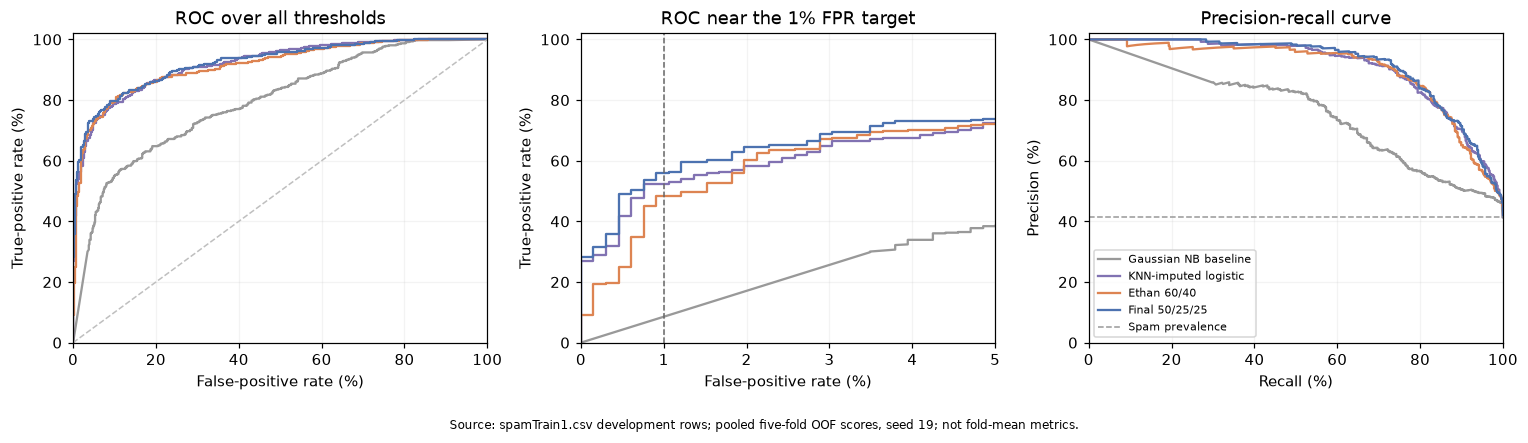

,Pooled AUC,Average precision
Model,,
Gaussian NB baseline,0.79418,0.73700
KNN-imputed logistic,0.92048,0.91010
Ethan 60/40,0.91452,0.90222
Final 50/25/25,0.92360,0.91662


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
curve_colors = ['0.6', '#8172b2', '#dd8452', '#4c72b0']
for name, color in zip(plot_names, curve_colors):
    scores = plot_oof[name]
    fpr, tpr, _ = roc_curve(y, scores)
    for ax in axes[:2]:
        ax.plot(100 * fpr, 100 * tpr, color=color, label=name)
    precision, recall, _ = precision_recall_curve(y, scores)
    axes[2].plot(100 * recall, 100 * precision, color=color, label=name)
axes[0].plot([0, 100], [0, 100], '--', color='0.75', linewidth=1)
axes[0].set(title='ROC over all thresholds', xlabel='False-positive rate (%)',
            ylabel='True-positive rate (%)', xlim=(0, 100), ylim=(0, 102))
axes[1].axvline(1, color='0.4', linestyle='--', linewidth=1)
axes[1].set(title='ROC near the 1% FPR target', xlabel='False-positive rate (%)',
            ylabel='True-positive rate (%)', xlim=(0, 5), ylim=(0, 102))
axes[2].axhline(100 * y.mean(), color='0.6', linestyle='--', linewidth=1,
               label='Spam prevalence')
axes[2].set(title='Precision-recall curve', xlabel='Recall (%)', ylabel='Precision (%)',
            xlim=(0, 100), ylim=(0, 102))
axes[2].legend(fontsize=7, loc='lower left')
for ax in axes:
    ax.grid(alpha=.15)
fig.text(.5, .01,
         f'Source: spamTrain1.csv development rows; pooled five-fold OOF scores, seed {seeds[0]}; not fold-mean metrics.',
         ha='center', fontsize=8)
fig.tight_layout(rect=(0, .06, 1, 1))
plt.show()
display(pd.DataFrame([
    {'Model': name, 'Pooled AUC': roc_auc_score(y, plot_oof[name]),
     'Average precision': average_precision_score(y, plot_oof[name])}
    for name in plot_names
]).set_index('Model').round(5))

## 5. Why these models together?

| Component | What it contributes | Important settings |
| --- | --- | --- |
| Binned logistic, 50% | Coarse absent/low/high frequency effects plus presence; missing values use training category proportions | `C=1`; boundary at midpoint of positive training min/max on log scale |
| RBF SVM, 25% | Nonlinear similarities between emails after filling missing log frequencies from neighbors | 31 neighbors; scaling after imputation; `C=10`, `gamma=.003` |
| Interaction logistic, 25% | Pairwise word-frequency/presence effects that an additive model misses | Mean imputation; 1,830 features; scaling; strong regularization `C=.001` |

Log features use `log1p(1000 × frequency)`. 

In [10]:
ablations = summarize(blend_results).reindex(blend_weights)
ablations['AUC_gain_vs_variant'] = ablations.loc['Final 50/25/25', 'AUC'] - ablations.AUC
ablations['TPR_gain_vs_variant_pp'] = ablations.loc['Final 50/25/25', 'TPR_percent'] - ablations.TPR_percent
display(ablations[['AUC', 'TPR_percent', 'AUC_gain_vs_variant', 'TPR_gain_vs_variant_pp']].round(5))
print('Gain columns = final trio minus the row. Positive favors the final trio; negative favors the row.')

paired = []
final_folds = final_rows.set_index(['Seed', 'Fold'])
for name in ['Without binned LR', 'Without RBF SVM', 'Without interactions']:
    variant = blend_results[blend_results.Model == name].set_index(['Seed', 'Fold'])
    delta = final_folds['TPR (%)'] - variant['TPR (%)']
    paired.append({'Variant': name, 'Trio TPR wins': int((delta > 1e-10).sum()),
                   'Ties': int((delta.abs() <= 1e-10).sum()), 'Trio TPR losses': int((delta < -1e-10).sum())})
display(pd.DataFrame(paired).set_index('Variant'))

Gain columns = final trio minus the row. Positive favors the final trio; negative favors the row.


,AUC,TPR_percent,AUC_gain_vs_variant,TPR_gain_vs_variant_pp
Model,,,,
Binned LR alone,0.91891,52.79204,0.00504,5.06955
RBF SVM alone,0.91819,49.35667,0.00576,8.50492
Interaction LR alone,0.91679,51.00641,0.00716,6.85518
Without binned LR,0.92234,55.71723,0.00161,2.14436
Without RBF SVM,0.92205,55.86205,0.00190,1.99954
Without interactions,0.92291,55.91146,0.00104,1.95013
Equal-weight trio,0.92439,57.62755,-0.00044,0.23404
Final 50/25/25,0.92395,57.86159,0.00000,0.00000


,Trio TPR wins,Ties,Trio TPR losses
Variant,,,
Without binned LR,28,2,20
Without RBF SVM,29,5,16
Without interactions,34,3,13


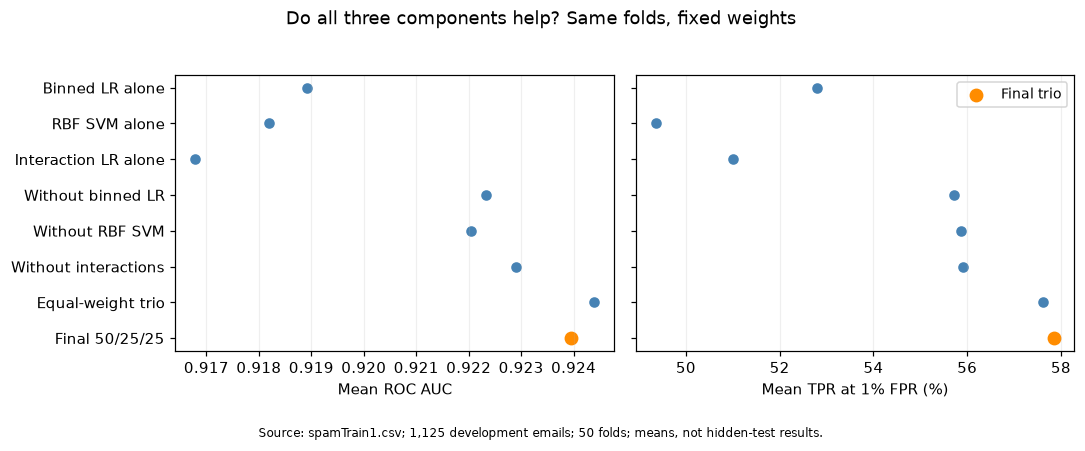

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
positions = np.arange(len(ablations))
for ax, metric, label in zip(axes, ['AUC', 'TPR_percent'], ['Mean ROC AUC', 'Mean TPR at 1% FPR (%)']):
    ax.scatter(ablations[metric], positions, color='steelblue', s=35)
    ax.scatter(ablations.loc['Final 50/25/25', metric], len(ablations)-1, color='darkorange', s=65, label='Final trio')
    ax.set(xlabel=label, yticks=positions, yticklabels=ablations.index)
    ax.grid(axis='x', alpha=.2)
axes[0].invert_yaxis()
axes[1].legend(loc='best', fontsize=9)
fig.suptitle('Do all three components help? Same folds, fixed weights')
fig.text(.5, .01, f'Source: spamTrain1.csv; 1,125 development emails; {5 * len(seeds)} folds; means, not hidden-test results.',
         ha='center', fontsize=8)
fig.tight_layout(rect=(0, .06, 1, .95))
plt.show()

The component-ablation table separates evidence for combining models from
evidence for the exact weights. Compare the equal-weight trio with 50/25/25 on
**both** metrics; a small AUC advantage can accompany a small low-FPR TPR loss.
The retained submission uses 50/25/25. These comparisons reuse development data
and do not establish a globally optimal weighting.

## 6. Threshold calibration and error inspection

Adapted from Ethan's exploration (`4c10633`), using our retained 50/25/25 ensemble.
The grader needs continuous scores; a deployed filter additionally needs a cutoff.
We divide **only the development rows** into 60% training, 20% calibration, and
20% evaluation (seed 340). The cutoff is selected using calibration labels only,
to maximize calibration recall while keeping empirical FPR at or below 1%.

These rows have already informed model selection, so this is a **diagnostic
partition, not an independent final test**. A cutoff calibrated to 1% FPR need
not achieve 1% on other emails. The cutoff below is illustrative and is not added
to `classifySpam.py`.

Training/calibration/evaluation emails: 675/225/225
Calibration-selected cutoff: 0.761594; score >= cutoff is flagged.
One calibration ham error changes FPR by 0.76 percentage points.


,Emails,TP,FP,TN,FN,Spam detected (%),Ham flagged (%)
Partition,,,,,,,
Calibration,225,52,1,131,41,55.91,0.76
Evaluation (diagnostic),225,52,2,130,41,55.91,1.52


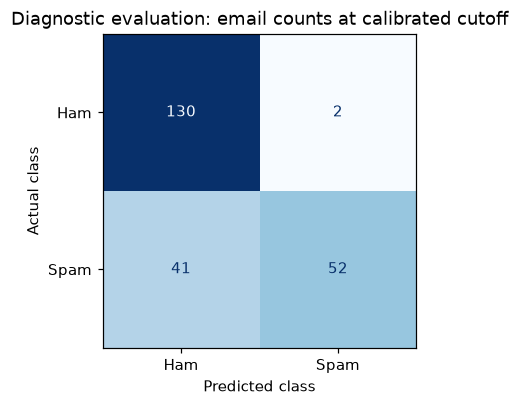

In [12]:
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

diag_train_cal, diag_evaluation = train_test_split(
    np.arange(len(y)), test_size=.2, stratify=y, random_state=340)
diag_train, diag_calibration = train_test_split(
    diag_train_cal, test_size=.25, stratify=y[diag_train_cal], random_state=340)
diag_models = list(component_models().values())
diag_ensemble = VotingClassifier(
    estimators=list(zip(('binned', 'svm', 'interactions'), diag_models)),
    voting='soft', weights=(.50, .25, .25))
with threadpool_limits(limits=2):
    diag_ensemble.fit(X[diag_train], y[diag_train])
    diag_cal_scores = diag_ensemble.predict_proba(X[diag_calibration])[:, 1]
    diag_eval_scores = diag_ensemble.predict_proba(X[diag_evaluation])[:, 1]
    np.testing.assert_allclose(
        diag_eval_scores, predictTest(X[diag_train], y[diag_train], X[diag_evaluation]),
        rtol=1e-9, atol=1e-10)

# Do not consult evaluation labels while selecting this cutoff.
cal_fpr, cal_tpr, cal_thresholds = roc_curve(
    y[diag_calibration], diag_cal_scores, drop_intermediate=False)
cal_index = np.flatnonzero(cal_fpr <= .01)[-1]
diag_threshold = cal_thresholds[cal_index]
diag_cal_predictions = (diag_cal_scores >= diag_threshold).astype(int)
diag_eval_predictions = (diag_eval_scores >= diag_threshold).astype(int)
assert np.mean(diag_cal_predictions[y[diag_calibration] == 0]) <= .01 + 1e-12

diag_rows = []
for label, indices, predictions in [
    ('Calibration', diag_calibration, diag_cal_predictions),
    ('Evaluation (diagnostic)', diag_evaluation, diag_eval_predictions),
]:
    tn, fp, fn, tp = confusion_matrix(y[indices], predictions, labels=[0, 1]).ravel()
    diag_rows.append({
        'Partition': label, 'Emails': len(indices), 'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn,
        'Spam detected (%)': 100 * tp / (tp + fn),
        'Ham flagged (%)': 100 * fp / (fp + tn),
    })
print(f'Training/calibration/evaluation emails: {len(diag_train)}/{len(diag_calibration)}/{len(diag_evaluation)}')
print(f'Calibration-selected cutoff: {diag_threshold:.6f}; score >= cutoff is flagged.')
print(f'One calibration ham error changes FPR by {100 / np.sum(y[diag_calibration] == 0):.2f} percentage points.')
display(pd.DataFrame(diag_rows).set_index('Partition').round(2))
fig, ax = plt.subplots(figsize=(4.6, 3.8))
ConfusionMatrixDisplay.from_predictions(
    y[diag_evaluation], diag_eval_predictions, labels=[0, 1],
    display_labels=['Ham', 'Spam'], cmap='Blues', colorbar=False, ax=ax)
ax.set_title('Diagnostic evaluation: email counts at calibrated cutoff')
ax.set_xlabel('Predicted class')
ax.set_ylabel('Actual class')
fig.tight_layout()
plt.show()

### Which emails are missed or incorrectly flagged?

Inspect up to five false positives and five false negatives, ranked by spam score
within each group. The row number locates an email in the original headerless CSV
(counting from 1). Feature counts describe missingness and observed word presence;
there are no message bodies or word names, so these examples cannot explain the
sender or meaning of an email. They suggest questions for future analysis, not
justification for tuning this cutoff on the evaluation labels.

In [13]:
diag_errors = pd.DataFrame({
    'CSV row (1-based)': development[diag_evaluation] + 1,
    'Actual class': np.where(y[diag_evaluation] == 1, 'Spam', 'Ham'),
    'Spam score': diag_eval_scores,
    'Predicted class': np.where(diag_eval_predictions == 1, 'Spam', 'Ham'),
    'Missing features': (X[diag_evaluation] == -1).sum(axis=1),
    'Observed present features': (X[diag_evaluation] > 0).sum(axis=1),
})
diag_errors = diag_errors[y[diag_evaluation] != diag_eval_predictions].copy()
diag_errors['Error type'] = np.where(
    diag_errors['Actual class'] == 'Ham', 'False positive', 'False negative')
if len(diag_errors):
    examples = (diag_errors.sort_values('Spam score', ascending=False)
                .groupby('Error type', sort=False).head(5)
                .sort_values(['Error type', 'Spam score'], ascending=[False, False]))
    print(f'{len(diag_errors)} threshold errors; showing at most five per type.')
    display(examples[['Error type', 'CSV row (1-based)', 'Actual class', 'Spam score',
                      'Predicted class', 'Missing features', 'Observed present features']]
            .reset_index(drop=True).round({'Spam score': 4}))
else:
    print('No threshold errors in this diagnostic partition.')

43 threshold errors; showing at most five per type.


,Error type,CSV row (1-based),Actual class,Spam score,Predicted class,Missing features,Observed present features
0,False positive,475,Ham,0.8528,Spam,3,5
1,False positive,464,Ham,0.8152,Spam,5,4
2,False negative,651,Spam,0.7569,Ham,8,5
3,False negative,891,Spam,0.7208,Ham,4,2
4,False negative,246,Spam,0.7070,Ham,6,5
5,False negative,281,Spam,0.7027,Ham,4,8
6,False negative,1167,Spam,0.6869,Ham,6,3


## 7. Previous research


The archived run explored **1,841 configurations**, re-evaluated 165 finalists,
and compared **29,000 ensemble weight/method combinations**. It also covered
Perceptron/Adaline, LDA/PCA, feature selection, gradient boosting/AdaBoost,
splines, alternative kernels, binning, and imputation.

- **KNN-imputed logistic:** its initial screening advantage in low-FPR detection did not persist in broader comparisons.
- **An all-logistic blend:** lost its advantage in the 50-holdout check.
- **High-AUC blends:** some sacrificed low-FPR detection, so AUC alone did not decide the model.
- **Automated nested selection:** underperformed the previous classifier. The search procedure itself was unstable.

In [14]:
# Compare executable function structure; docstrings/formatting do not change the model.
import ast
recorded_csv_hash = '1cc074784a0c6dc05b2e784ae9f38e1a76886f168f904720d93a755342e15df5'
recorded_function_hash = 'c6407900dcf7c5457054f0fa298ac256902c21bc45e30f88b15aa9f679665c3e'
function_tree = next(node for node in ast.parse(Path('classifySpam.py').read_text()).body
                     if isinstance(node, ast.FunctionDef) and node.name == 'predictTest')
first_statement = function_tree.body[0]
if (isinstance(first_statement, ast.Expr) and isinstance(first_statement.value, ast.Constant)
        and isinstance(first_statement.value.value, str)):
    function_tree.body.pop(0)
matches_record = (
    hashlib.sha256(Path('spamTrain1.csv').read_bytes()).hexdigest() == recorded_csv_hash
    and hashlib.sha256(ast.dump(function_tree).encode()).hexdigest() == recorded_function_hash
)
if matches_record:
    historical = pd.DataFrame([
        ['Previous ensemble', 0.9221003556710096, 55.22077327842598],
        ['Final ensemble', 0.9239492662218174, 57.86158773735986],
    ], columns=['Model', 'Mean AUC', 'Mean TPR at 1% FPR (%)']).set_index('Model')
    print('Historical archive results, recorded October 25, 2026; not a new validation run:')
    display(historical.round(5))
else:
    print('Data or model logic changed: historical results describe the archived version only.')

Historical archive results, recorded October 25, 2026; not a new validation run:


,Mean AUC,Mean TPR at 1% FPR (%)
Model,,
Previous ensemble,0.92210,55.22077
Final ensemble,0.92395,57.86159


The archived gain over the previous ensemble was **+0.00185 AUC** and
**+2.64 percentage points TPR**. The previous ensemble is a historical Ha model,
not Ethan's 60/40 model. The fresh branch comparison is in section 4.

## 8. Limitations and submission

- **Small low-FPR sample:** each main validation fold has about 132 ham emails;
  one or two high-scoring ham emails can move TPR sharply.
- **Selection bias:** these emails informed model and weight selection. Additional
  split seeds create different partitions, not independent observations.
- **Diagnostic threshold:** the threshold in section 6 is fitted on calibration
  labels only, but its evaluation partition comes from reused development data.
  It is not an independent hidden test and its FPR can exceed the calibration target.
- **Anonymous features:** feature IDs identify columns, not known words; associations
  do not establish causes or justify claims about message content.
- **Submission:** retain `classifySpam.py` and its exact `predictTest` interface.
  It returns continuous spam scores; do not replace them with thresholded labels.
  All models train from the arrays supplied by the evaluator.
- **Next evidence:** evaluate the frozen model on separately released labeled test
  data when available. `evaluateClassifier.py` currently expects `spamTrain2.csv`,
  which is not included here. Do not substitute the training CSV as the test set.

AUC measures ranking, not classification accuracy. TPR at 1% FPR describes spam
detected while flagging 1% of ham under the interpolated ROC metric. Runtime and
small score differences can depend on the installed scikit-learn version.